# Part-5: Deep Learning for Time Series (RNN, LSTM, GRU, CNN, Transformer)

**Time Series in Machine Learning** — Daneshkar.net

---


In [1]:
# Install required packages (uncomment if needed)
# %pip install numpy
# %pip install pandas
# %pip install matplotlib
# %pip install scikit-learn
# %pip install torch

# Or install all at once:
# %pip install numpy pandas matplotlib scikit-learn torch


In [2]:
# Common imports & Jupyter setup
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os, warnings
warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 100
print("Setup complete! Ready to run.")


Setup complete! Ready to run.


---
## Intro Deep Learning Sequences


In [3]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

OUTPUT_DIR = os.getcwd()  # current working directory (Jupyter)
device = torch.device("cpu")
# Note: Change to torch.device("cuda" if torch.cuda.is_available() else "cpu") for GPU
print(f"Using device: {device}")
print("Output directory: Part-5/")


Using device: cpu
Output directory: Part-5/


## 1. Create synthetic time series


In [4]:
def create_synthetic_series(n_points: int = 800, seed: int = 42) -> np.ndarray:
    """Create a synthetic time series with trend, seasonality, and noise."""
    rng = np.random.RandomState(seed)
    t = np.arange(n_points, dtype=np.float32)
    trend = 0.05 * t
    seasonality = 5.0 * np.sin(2 * np.pi * t / 60.0) + 3.0 * np.sin(2 * np.pi * t / 20.0)
    noise = rng.normal(0, 1.5, size=n_points)
    return trend + seasonality + noise


## 2. Sequence creation — sliding window to 3D tensor


In [5]:
def create_sequences(data: np.ndarray, seq_length: int):
    """
    Convert a 1D/2D time series into (X, y) supervised-learning pairs.

    Parameters
    ----------
    data : np.ndarray
        Shape (n_timesteps,) or (n_timesteps, n_features).
    seq_length : int
        Number of past time steps to use as input.

    Returns
    -------
    X : np.ndarray, shape (n_sequences, seq_length, n_features)
    y : np.ndarray, shape (n_sequences,)
    """
    if data.ndim == 1:
        data = data.reshape(-1, 1)
    X, y = [], []
    n_features = data.shape[1]
    for i in range(len(data) - seq_length):
        X.append(data[i : i + seq_length])
        y.append(data[i + seq_length, -1] if n_features > 1 else data[i + seq_length, 0])
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)


## 3. Data preparation pipeline (MinMaxScaler, time-based split, DataLoader)


In [6]:
def prepare_dl_data(data, seq_length: int = 30, train_ratio: float = 0.8, batch_size: int = 32):
    """
    End-to-end data preparation for deep learning:
      - Scale with MinMaxScaler (fit on train only)
      - Create sequences
      - Time-based (non-random) split
      - Return DataLoaders and scaler
    """
    scaler = MinMaxScaler(feature_range=(0, 1))
    data_scaled = scaler.fit_transform(data.reshape(-1, 1)).astype(np.float32)

    X_all, y_all = create_sequences(data_scaled, seq_length)

    # Time-based split: first train_ratio fraction for training
    split_idx = int(len(X_all) * train_ratio)
    X_train, X_test = X_all[:split_idx], X_all[split_idx:]
    y_train, y_test = y_all[:split_idx], y_all[split_idx:]

    # Convert to PyTorch tensors
    X_pt = torch.FloatTensor(X_train)
    y_pt = torch.FloatTensor(y_train)
    X_test_pt = torch.FloatTensor(X_test)
    y_test_pt = torch.FloatTensor(y_test)

    train_ds = TensorDataset(X_pt, y_pt)
    test_ds = TensorDataset(X_test_pt, y_test_pt)

    # IMPORTANT: shuffle=False for time series — temporal order must be preserved!
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

    print(f"Data shapes — X_train: {X_train.shape}, y_train: {y_train.shape}")
    print(f"              X_test:  {X_test.shape},  y_test:  {y_test.shape}")
    return train_loader, test_loader, (X_test, y_test), scaler


## 4. Simple MLP model (baseline — ignores sequential structure)


In [7]:
class SimpleMLP(nn.Module):
    """
    A simple multi-layer perceptron for time-series forecasting.
    The input is flattened, losing all temporal structure.
    This is intentionally a weak baseline.
    """
    def __init__(self, seq_length: int, hidden_sizes=None):
        super().__init__()
        if hidden_sizes is None:
            hidden_sizes = [64, 32]
        layers = []
        in_dim = seq_length
        for h in hidden_sizes:
            layers.extend([nn.Linear(in_dim, h), nn.ReLU(), nn.Dropout(0.2)])
            in_dim = h
        layers.append(nn.Linear(in_dim, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        # x: (batch, seq_len, n_features) -> flatten -> (batch, seq_len * n_features)
        return self.net(x.view(x.size(0), -1)).squeeze(-1)


## 5. Training loop with ReduceLROnPlateau


In [8]:
def train_model(model, train_loader, val_loader, epochs: int = 20, lr: float = 0.001):
    model.to(device)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=5
    )

    history = {"train_loss": [], "val_loss": []}
    best_val = float("inf")
    best_state = None

    for epoch in range(1, epochs + 1):
        # ---- Training ----
        model.train()
        train_loss = 0.0
        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            loss = criterion(model(bx), by)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            train_loss += loss.item() * bx.size(0)
        train_loss /= len(train_loader.dataset)
        history["train_loss"].append(train_loss)

        # ---- Validation ----
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for bx, by in val_loader:
                bx, by = bx.to(device), by.to(device)
                loss = criterion(model(bx), by)
                val_loss += loss.item() * bx.size(0)
        val_loss /= len(val_loader.dataset)
        history["val_loss"].append(val_loss)

        scheduler.step(val_loss)
        if val_loss < best_val:
            best_val = val_loss
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

        if epoch % 5 == 0 or epoch == epochs:
            lr_now = optimizer.param_groups[0]["lr"]
            print(f"Epoch {epoch:3d}/{epochs} | Train Loss: {train_loss:.6f} | Val Loss: {val_loss:.6f} | LR: {lr_now:.2e}")

    # Restore best weights
    if best_state is not None:
        model.load_state_dict(best_state)
    return history


## 6. Evaluation and plotting


In [9]:
def evaluate_and_plot(model, X_test_raw, y_test_raw, scaler, history, output_dir, tag="MLP"):
    """Evaluate model, print metrics, and save plots."""
    model.eval()
    with torch.no_grad():
        preds_scaled = model(torch.FloatTensor(X_test_raw).to(device)).cpu().numpy()

    preds = scaler.inverse_transform(preds_scaled.reshape(-1, 1)).flatten()
    actuals = scaler.inverse_transform(y_test_raw.reshape(-1, 1)).flatten()

    rmse = float(np.sqrt(mean_squared_error(actuals, preds)))
    mae = float(mean_absolute_error(actuals, preds))
    mape = float(np.mean(np.abs((actuals - preds) / (actuals + 1e-8))) * 100)

    print(f"\n{tag} Results:")
    print(f"  RMSE: {rmse:.4f}")
    print(f"  MAE:  {mae:.4f}")
    print(f"  MAPE: {mape:.2f}%")

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    # Time series
    axes[0].plot(actuals, label="Actual", linewidth=2)
    axes[0].plot(preds, label="Predicted", alpha=0.8)
    axes[0].set_title(f"{tag} — Time Series Forecast (RMSE={rmse:.4f})")
    axes[0].set_xlabel("Time Step")
    axes[0].set_ylabel("Value")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Scatter
    axes[1].scatter(actuals, preds, alpha=0.5)
    lo = min(actuals.min(), preds.min())
    hi = max(actuals.max(), preds.max())
    axes[1].plot([lo, hi], [lo, hi], "r--", linewidth=1)
    axes[1].set_xlabel("Actual")
    axes[1].set_ylabel("Predicted")
    axes[1].set_title("Scatter Plot")
    axes[1].grid(True, alpha=0.3)

    # Training history
    axes[2].plot(history["train_loss"], label="Train")
    axes[2].plot(history["val_loss"], label="Validation")
    axes[2].set_xlabel("Epoch")
    axes[2].set_ylabel("Loss (MSE)")
    axes[2].set_title("Training History")
    axes[2].set_yscale("log")
    axes[2].legend()
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    path = os.path.join(output_dir, f"{tag.lower()}_forecast.png")
    print(f"Plot saved to: {os.path.basename(path)}")
    return preds, actuals


## 7. Main demo


Deep Learning for Time Series — Introduction Demo

Generated 600 data points.
Data shapes — X_train: (456, 30, 1), y_train: (456,)
              X_test:  (114, 30, 1),  y_test:  (114,)

MLP parameters: 4,097
SimpleMLP(
  (net): Sequential(
    (0): Linear(in_features=30, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)
Epoch   5/20 | Train Loss: 0.019398 | Val Loss: 0.011782 | LR: 1.00e-03
Epoch  10/20 | Train Loss: 0.016071 | Val Loss: 0.008787 | LR: 1.00e-03
Epoch  15/20 | Train Loss: 0.013815 | Val Loss: 0.010235 | LR: 1.00e-03
Epoch  20/20 | Train Loss: 0.011171 | Val Loss: 0.004839 | LR: 1.00e-03

MLP Results:
  RMSE: 2.9912
  MAE:  2.3913
  MAPE: 8.85%
Plot saved to: mlp_forecast.png

Key Takeaways:
  - Time series data must be shaped (samples, seq_len, features)
  - Al

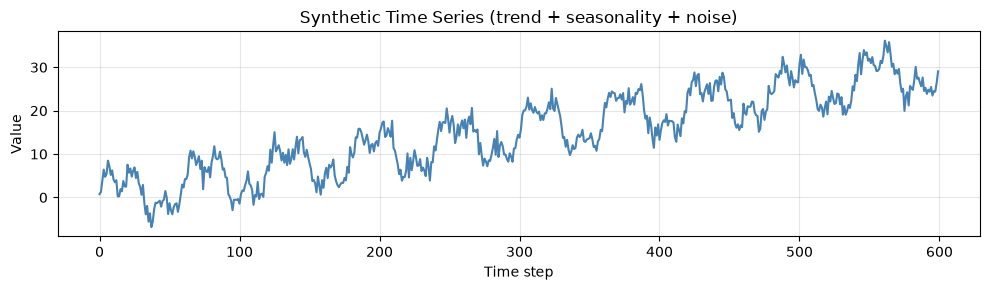

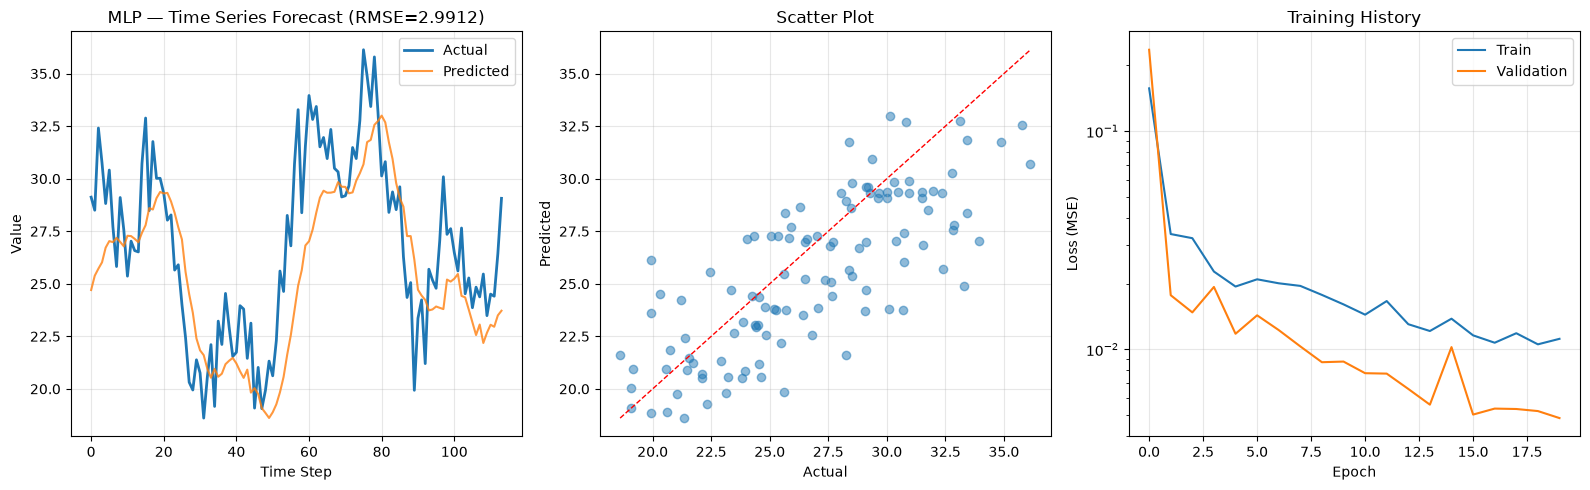

In [10]:
def main():
    print("=" * 60)
    print("Deep Learning for Time Series — Introduction Demo")
    print("=" * 60)

    # Generate data
    data = create_synthetic_series(n_points=600)
    plt.figure(figsize=(10, 3))
    plt.plot(data, color="steelblue")
    plt.title("Synthetic Time Series (trend + seasonality + noise)")
    plt.xlabel("Time step")
    plt.ylabel("Value")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "synthetic_series.png"), dpi=150)
    print(f"\nGenerated {len(data)} data points.")

    # Prepare data
    seq_length = 30
    train_loader, test_loader, (X_test, y_test), scaler = prepare_dl_data(
        data, seq_length=seq_length, train_ratio=0.8, batch_size=32
    )

    # Build and train MLP
    model = SimpleMLP(seq_length=seq_length, hidden_sizes=[64, 32])
    n_params = sum(p.numel() for p in model.parameters())
    print(f"\nMLP parameters: {n_params:,}")
    print(model)

    history = train_model(model, train_loader, test_loader, epochs=20, lr=0.001)

    # Evaluate
    evaluate_and_plot(model, X_test, y_test, scaler, history, OUTPUT_DIR, tag="MLP")

    print("\n" + "=" * 60)
    print("Key Takeaways:")
    print("  - Time series data must be shaped (samples, seq_len, features)")
    print("  - Always use time-based split, never random shuffle")
    print("  - MinMaxScaler: fit on train only, transform both train and test")
    print("  - MLP ignores temporal structure — not suited for sequences")
    print("  - RNN/LSTM/GRU families are designed for sequential data")
    print("=" * 60)


if __name__ == "__main__":
    main()


---
## RNN


In [11]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

OUTPUT_DIR = os.getcwd()  # current working directory (Jupyter)
device = torch.device("cpu")
# Note: Change to torch.device("cuda" if torch.cuda.is_available() else "cpu") for GPU
print(f"Using device: {device}")
print("Output directory: Part-5/")


Using device: cpu
Output directory: Part-5/


## 1. Synthetic data generation


In [12]:
def generate_synthetic_data(n_points: int = 500, seed: int = 42):
    """Generate a synthetic time series with trend + seasonality + noise."""
    rng = np.random.RandomState(seed)
    t = np.arange(n_points, dtype=np.float32)
    trend = 0.1 * t
    seasonal = 5.0 * np.sin(2 * np.pi * t / 50.0)
    noise = rng.normal(0, 1.0, size=n_points)
    return trend + seasonal + noise


def create_sequences(data: np.ndarray, seq_length: int):
    """Sliding window: returns (X, y) for supervised forecasting."""
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i : i + seq_length])
        y.append(data[i + seq_length])
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)


## 2. SimpleRNN model class


In [13]:
class SimpleRNN(nn.Module):
    """
    Vanilla RNN for time-series forecasting.

    Parameters
    ----------
    input_size : int
        Number of features at each time step.
    hidden_size : int
        Number of units in the hidden state.
    num_layers : int
        Number of stacked RNN layers.
    dropout : float
        Dropout rate applied between RNN layers (ignored if num_layers == 1).
    """
    def __init__(self, input_size: int = 1, hidden_size: int = 64,
                 num_layers: int = 2, dropout: float = 0.2):
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers

        self.rnn = nn.RNN(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            dropout=dropout if num_layers > 1 else 0.0,
            batch_first=True,
            nonlinearity="tanh",
        )
        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        # x: (batch, seq_len, input_size)
        rnn_out, _ = self.rnn(x)             # (batch, seq_len, hidden_size)
        last_out = rnn_out[:, -1, :]          # (batch, hidden_size)
        return self.fc(last_out).squeeze(-1)  # (batch,)


## 3. RNN Trainer with gradient clipping


In [14]:
class RNNTrainer:
    """
    Complete training/evaluation pipeline for RNN models.
    """
    def __init__(self, model, device):
        self.model = model.to(device)
        self.device = device
        self.criterion = nn.MSELoss()
        self.optimizer = None

    def fit(self, train_loader, val_loader=None, epochs: int = 50, lr: float = 0.001):
        self.optimizer = optim.Adam(self.model.parameters(), lr=lr)
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(
            self.optimizer, mode="min", factor=0.5, patience=5
        )
        history = {"train_loss": [], "val_loss": []}
        best_val = float("inf")
        best_state = None

        for epoch in range(1, epochs + 1):
            # ---- Training ----
            self.model.train()
            train_loss = 0.0
            for bx, by in train_loader:
                bx, by = bx.to(self.device), by.to(self.device)
                self.optimizer.zero_grad()
                preds = self.model(bx)
                loss = self.criterion(preds, by)
                loss.backward()
                # Gradient clipping — prevents exploding gradients common in RNNs
                nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=1.0)
                self.optimizer.step()
                train_loss += loss.item() * bx.size(0)
            train_loss /= len(train_loader.dataset)
            history["train_loss"].append(train_loss)

            # ---- Validation ----
            val_loss = float("nan")
            if val_loader is not None:
                self.model.eval()
                val_loss = 0.0
                with torch.no_grad():
                    for bx, by in val_loader:
                        bx, by = bx.to(self.device), by.to(self.device)
                        loss = self.criterion(self.model(bx), by)
                        val_loss += loss.item() * bx.size(0)
                val_loss /= len(val_loader.dataset)
                history["val_loss"].append(val_loss)
                scheduler.step(val_loss)

                if val_loss < best_val:
                    best_val = val_loss
                    best_state = {k: v.cpu().clone() for k, v in self.model.state_dict().items()}

            if epoch % 10 == 0 or epoch == epochs:
                msg = f"Epoch {epoch:3d}/{epochs} | Train Loss: {train_loss:.6f}"
                if val_loader is not None:
                    msg += f" | Val Loss: {val_loss:.6f}"
                print(msg)

        # Restore best weights
        if best_state is not None:
            self.model.load_state_dict(best_state)
        return history

    def predict(self, X):
        """Generate predictions for a numpy array X."""
        self.model.eval()
        with torch.no_grad():
            preds = self.model(torch.FloatTensor(X).to(self.device)).cpu().numpy()
        return preds


## 4. Plotting helper


In [15]:
def plot_forecast(actuals, predictions, history, title="RNN Forecast", output_dir=OUTPUT_DIR):
    """Plot time-series forecast, scatter, and training history."""
    rmse = float(np.sqrt(mean_squared_error(actuals, predictions)))
    mae = float(mean_absolute_error(actuals, predictions))

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    # Time series
    axes[0].plot(actuals, label="Actual", linewidth=2)
    axes[0].plot(predictions, label="Predicted", alpha=0.8)
    axes[0].set_title(f"{title} — RMSE={rmse:.4f}, MAE={mae:.4f}")
    axes[0].set_xlabel("Time Step")
    axes[0].set_ylabel("Value")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Scatter
    axes[1].scatter(actuals, predictions, alpha=0.5)
    lo = min(actuals.min(), predictions.min())
    hi = max(actuals.max(), predictions.max())
    axes[1].plot([lo, hi], [lo, hi], "r--", linewidth=1)
    axes[1].set_xlabel("Actual")
    axes[1].set_ylabel("Predicted")
    axes[1].set_title("Scatter Plot")
    axes[1].grid(True, alpha=0.3)

    # Training history
    if history:
        axes[2].plot(history["train_loss"], label="Train")
        if "val_loss" in history and history["val_loss"]:
            axes[2].plot(history["val_loss"], label="Validation")
        axes[2].set_xlabel("Epoch")
        axes[2].set_ylabel("Loss (MSE)")
        axes[2].set_title("Training History")
        axes[2].set_yscale("log")
        axes[2].legend()
        axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    path = os.path.join(output_dir, "rnn_forecast.png")
    print(f"Plot saved to: {os.path.basename(path)}")


## 5. Main demo


RNN — Recurrent Neural Network for Time Series
Train: (376, 30, 1), Test: (94, 30, 1)

RNN parameters: 14,721
SimpleRNN(
  (rnn): RNN(1, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
  )
)
Epoch  10/30 | Train Loss: 0.024259 | Val Loss: 0.056147
Epoch  20/30 | Train Loss: 0.011008 | Val Loss: 0.018613
Epoch  30/30 | Train Loss: 0.010279 | Val Loss: 0.015445
Plot saved to: rnn_forecast.png

Final RNN RMSE: 5.6375

RNN Limitations (Why We Need LSTM / GRU):
  1. Vanishing gradient — RNN cannot learn dependencies beyond ~20 steps
  2. Exploding gradient — gradients can grow uncontrollably (clipping helps)
  3. No gating mechanism — the hidden state is a simple tanh transformation
  4. LSTM and GRU address these with forget/input/output gates


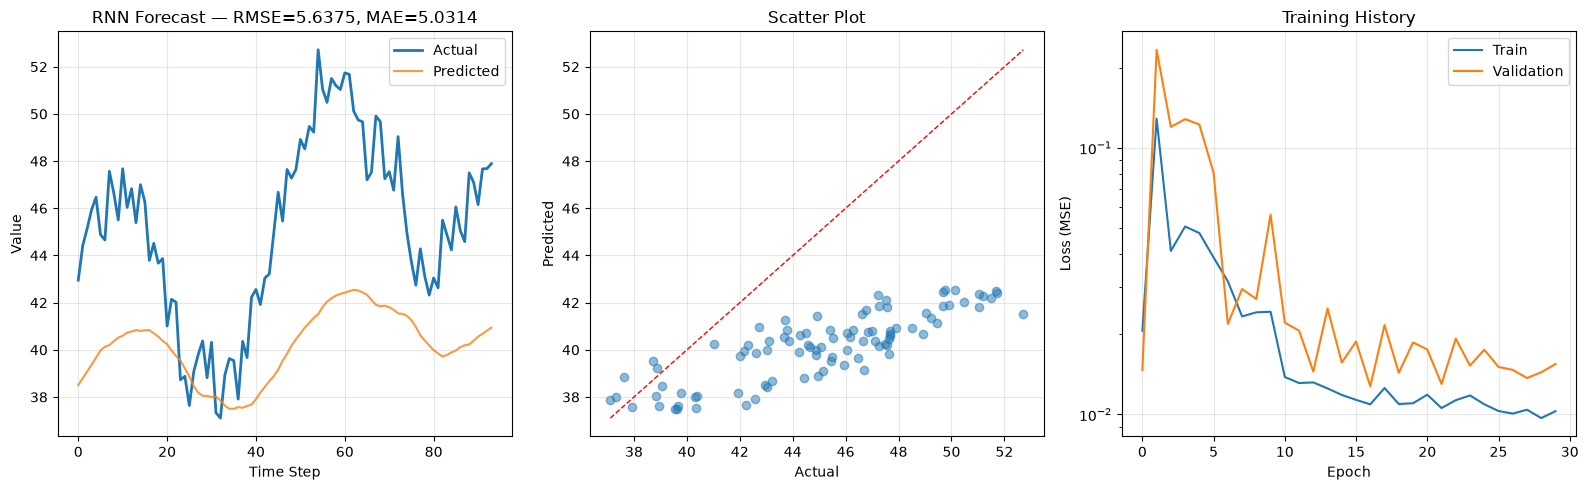

In [16]:
def main():
    print("=" * 60)
    print("RNN — Recurrent Neural Network for Time Series")
    print("=" * 60)

    # ---- Data ----
    data = generate_synthetic_data(n_points=500)
    scaler = MinMaxScaler()
    data_scaled = scaler.fit_transform(data.reshape(-1, 1)).astype(np.float32)

    seq_length = 30
    X, y = create_sequences(data_scaled, seq_length)

    # Time-based split
    split = int(len(X) * 0.8)
    X_train, X_test = X[:split], X[split:]
    y_train, y_test = y[:split], y[split:]
    print(f"Train: {X_train.shape}, Test: {X_test.shape}")

    # DataLoaders
    train_ds = TensorDataset(torch.FloatTensor(X_train), torch.FloatTensor(y_train))
    test_ds = TensorDataset(torch.FloatTensor(X_test), torch.FloatTensor(y_test))
    train_loader = DataLoader(train_ds, batch_size=32, shuffle=False)
    test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)

    # ---- Model ----
    model = SimpleRNN(input_size=1, hidden_size=64, num_layers=2, dropout=0.2)
    n_params = sum(p.numel() for p in model.parameters())
    print(f"\nRNN parameters: {n_params:,}")
    print(model)

    # ---- Training ----
    trainer = RNNTrainer(model, device=device)
    history = trainer.fit(train_loader, test_loader, epochs=30, lr=0.001)

    # ---- Evaluation ----
    preds_scaled = trainer.predict(X_test)
    preds = scaler.inverse_transform(preds_scaled.reshape(-1, 1)).flatten()
    actuals = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()

    plot_forecast(actuals, preds, history, title="RNN Forecast", output_dir=OUTPUT_DIR)

    rmse = float(np.sqrt(mean_squared_error(actuals, preds)))
    print(f"\nFinal RNN RMSE: {rmse:.4f}")

    # ---- Comparison note ----
    print("\n" + "=" * 60)
    print("RNN Limitations (Why We Need LSTM / GRU):")
    print("  1. Vanishing gradient — RNN cannot learn dependencies beyond ~20 steps")
    print("  2. Exploding gradient — gradients can grow uncontrollably (clipping helps)")
    print("  3. No gating mechanism — the hidden state is a simple tanh transformation")
    print("  4. LSTM and GRU address these with forget/input/output gates")
    print("=" * 60)


if __name__ == "__main__":
    main()


---
## LSTM


In [17]:
import os
import copy
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

OUTPUT_DIR = os.getcwd()  # current working directory (Jupyter)
device = torch.device("cpu")
# Note: Change to torch.device("cuda" if torch.cuda.is_available() else "cpu") for GPU
print(f"Using device: {device}")
print("Output directory: Part-5/")


Using device: cpu
Output directory: Part-5/


## 1. Synthetic data


In [18]:
def generate_synthetic_data(n_points: int = 500, seed: int = 42):
    rng = np.random.RandomState(seed)
    t = np.arange(n_points, dtype=np.float32)
    trend = 0.05 * t
    seasonal = 5.0 * np.sin(2 * np.pi * t / 40.0) + 2.0 * np.sin(2 * np.pi * t / 15.0)
    noise = rng.normal(0, 1.0, size=n_points)
    return (trend + seasonal + noise).reshape(-1, 1)


## 2. LSTMForecaster — configurable layers, dropout, bidirectional


In [19]:
class LSTMForecaster(nn.Module):
    """
    LSTM-based forecaster with configurable depth, dropout, and bidirectionality.

    Parameters
    ----------
    input_size : int       Number of input features per time step.
    hidden_size : int      Number of LSTM hidden units.
    num_layers : int       Number of stacked LSTM layers.
    dropout : float        Dropout rate (applied between layers if num_layers > 1).
    bidirectional : bool   If True, use a bidirectional LSTM.
    """
    def __init__(self, input_size=1, hidden_size=128, num_layers=2,
                 dropout=0.2, bidirectional=False):
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.bidirectional = bidirectional
        num_directions = 2 if bidirectional else 1

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            dropout=dropout if num_layers > 1 else 0.0,
            batch_first=True,
            bidirectional=bidirectional,
        )
        lstm_out_dim = hidden_size * num_directions
        self.fc = nn.Sequential(
            nn.Linear(lstm_out_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        # x: (batch, seq_len, input_size)
        lstm_out, _ = self.lstm(x)          # (batch, seq_len, hidden*num_dir)
        last_out = lstm_out[:, -1, :]        # (batch, hidden*num_dir)
        return self.fc(last_out).squeeze(-1)  # (batch,)


## 3. MultivariateLSTM with attention


In [20]:
class MultivariateLSTM(nn.Module):
    """
    LSTM for multivariate time series with additive attention.

    The attention mechanism computes a weighted average over all LSTM
    output steps, allowing the model to focus on the most relevant
    time steps rather than just the last one.
    """
    def __init__(self, input_size, hidden_size=128, num_layers=2,
                 dropout=0.2, output_size=1):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            dropout=dropout if num_layers > 1 else 0.0,
            batch_first=True,
        )
        # Attention: one score per time step
        self.attn = nn.Linear(hidden_size, 1)
        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, output_size),
        )

    def forward(self, x):
        # x: (batch, seq_len, input_size)
        lstm_out, _ = self.lstm(x)                # (batch, seq_len, hidden)
        # Attention weights
        attn_scores = self.attn(lstm_out).squeeze(-1)  # (batch, seq_len)
        attn_weights = torch.softmax(attn_scores, dim=1)
        # Weighted context vector
        context = (lstm_out * attn_weights.unsqueeze(-1)).sum(dim=1)  # (batch, hidden)
        return self.fc(context).squeeze(-1)


## 4. LSTMTimeSeries — complete pipeline class


In [21]:
class LSTMTimeSeries:
    """
    End-to-end LSTM pipeline for time-series forecasting.

    Features:
      - Data preparation with MinMaxScaler
      - Fit with early stopping and ReduceLROnPlateau
      - Predict
      - Recursive multi-step forecast_future
      - plot_results (time series, scatter, training history)
    """
    def __init__(self, input_size=1, hidden_size=128, num_layers=2,
                 dropout=0.2, learning_rate=0.001, device=device):
        self.device = device
        self.model = LSTMForecaster(
            input_size, hidden_size, num_layers, dropout
        ).to(device)
        self.criterion = nn.MSELoss()
        self.optimizer = optim.Adam(self.model.parameters(), lr=learning_rate)
        self.scheduler = optim.lr_scheduler.ReduceLROnPlateau(
            self.optimizer, mode="min", factor=0.5, patience=5
        )
        self.scaler_X = MinMaxScaler()
        self.scaler_y = MinMaxScaler()
        self.history = {"train_loss": [], "val_loss": []}
        self.best_state = None

    def prepare_data(self, data, seq_length, target_col=-1):
        """
        Scale data and create (X, y) sequences.

        Parameters
        ----------
        data : np.ndarray  Shape (n_timesteps,) or (n_timesteps, n_features).
        seq_length : int   Number of past steps as input.
        target_col : int   Index of the target column.

        Returns
        -------
        X : np.ndarray  (n_sequences, seq_length, n_features)
        y : np.ndarray  (n_sequences,)
        """
        if data.ndim == 1:
            data = data.reshape(-1, 1)
        data_scaled = self.scaler_X.fit_transform(data)
        self.scaler_y.fit(data[:, [target_col]])

        X, y = [], []
        for i in range(len(data_scaled) - seq_length):
            X.append(data_scaled[i : i + seq_length])
            y.append(data_scaled[i + seq_length, target_col])
        return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)

    def fit(self, X, y, validation_split=0.2, epochs=50, batch_size=32, patience=10, verbose=True):
        """Train the LSTM model with early stopping."""
        split_idx = int(len(X) * (1 - validation_split))
        X_tr, X_val = X[:split_idx], X[split_idx:]
        y_tr, y_val = y[:split_idx], y[split_idx:]

        tr_loader = DataLoader(
            TensorDataset(torch.FloatTensor(X_tr).to(self.device),
                          torch.FloatTensor(y_tr).to(self.device)),
            batch_size=batch_size, shuffle=False,
        )
        val_loader = DataLoader(
            TensorDataset(torch.FloatTensor(X_val).to(self.device),
                          torch.FloatTensor(y_val).to(self.device)),
            batch_size=batch_size, shuffle=False,
        )

        best_val = float("inf")
        patience_counter = 0

        for epoch in range(1, epochs + 1):
            # Train
            self.model.train()
            train_loss = 0.0
            for bx, by in tr_loader:
                self.optimizer.zero_grad()
                loss = self.criterion(self.model(bx), by)
                loss.backward()
                nn.utils.clip_grad_norm_(self.model.parameters(), 1.0)
                self.optimizer.step()
                train_loss += loss.item() * bx.size(0)
            train_loss /= len(tr_loader.dataset)
            self.history["train_loss"].append(train_loss)

            # Validate
            self.model.eval()
            val_loss = 0.0
            with torch.no_grad():
                for bx, by in val_loader:
                    loss = self.criterion(self.model(bx), by)
                    val_loss += loss.item() * bx.size(0)
            val_loss /= len(val_loader.dataset)
            self.history["val_loss"].append(val_loss)
            self.scheduler.step(val_loss)

            if val_loss < best_val:
                best_val = val_loss
                patience_counter = 0
                self.best_state = copy.deepcopy(self.model.state_dict())
            else:
                patience_counter += 1

            if verbose and (epoch % 10 == 0 or epoch == epochs):
                lr = self.optimizer.param_groups[0]["lr"]
                print(f"Epoch {epoch:3d}/{epochs} | Train: {train_loss:.6f} | "
                      f"Val: {val_loss:.6f} | LR: {lr:.2e}")

            if patience_counter >= patience:
                print(f"Early stopping triggered at epoch {epoch}")
                break

        if self.best_state is not None:
            self.model.load_state_dict(self.best_state)
        return self.history

    def predict(self, X):
        """Predict on numpy array X."""
        self.model.eval()
        with torch.no_grad():
            return self.model(torch.FloatTensor(X).to(self.device)).cpu().numpy()

    def forecast_future(self, last_sequence, steps, n_features=1):
        """
        Recursive multi-step forecasting.

        Parameters
        ----------
        last_sequence : np.ndarray  Shape (seq_length, n_features).
        steps : int                 Number of future steps to forecast.
        n_features : int

        Returns
        -------
        forecasts : np.ndarray  Shape (steps,)
        """
        self.model.eval()
        seq = last_sequence.copy()
        forecasts = []
        for _ in range(steps):
            inp = torch.FloatTensor(seq).unsqueeze(0).to(self.device)
            with torch.no_grad():
                pred = self.model(inp).item()
            forecasts.append(pred)
            new_row = np.zeros((1, n_features), dtype=np.float32)
            new_row[0, 0] = pred
            seq = np.concatenate([seq[1:], new_row], axis=0)
        return np.array(forecasts)

    def plot_results(self, y_true, y_pred, title="LSTM Forecast"):
        """Three-panel plot: time series, scatter, training history."""
        rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
        mae = float(mean_absolute_error(y_true, y_pred))

        fig, axes = plt.subplots(1, 3, figsize=(16, 5))

        axes[0].plot(y_true, label="Actual", linewidth=2)
        axes[0].plot(y_pred, label="Predicted", alpha=0.8)
        axes[0].set_title(f"{title}\nRMSE={rmse:.4f}, MAE={mae:.4f}")
        axes[0].set_xlabel("Time Step")
        axes[0].set_ylabel("Value")
        axes[0].legend()
        axes[0].grid(True, alpha=0.3)

        lo = min(y_true.min(), y_pred.min())
        hi = max(y_true.max(), y_pred.max())
        axes[1].scatter(y_true, y_pred, alpha=0.5)
        axes[1].plot([lo, hi], [lo, hi], "r--", linewidth=1)
        axes[1].set_xlabel("Actual")
        axes[1].set_ylabel("Predicted")
        axes[1].set_title("Scatter Plot")
        axes[1].grid(True, alpha=0.3)

        if self.history["train_loss"]:
            axes[2].plot(self.history["train_loss"], label="Train")
            axes[2].plot(self.history["val_loss"], label="Validation")
            axes[2].set_xlabel("Epoch")
            axes[2].set_ylabel("Loss (MSE)")
            axes[2].set_title("Training History")
            axes[2].set_yscale("log")
            axes[2].legend()
            axes[2].grid(True, alpha=0.3)

        plt.tight_layout()
        path = os.path.join(OUTPUT_DIR, "lstm_forecast.png")
        print(f"Plot saved to: {os.path.basename(path)}")


## 5. Main demo


LSTM — Long Short-Term Memory Demo
Data shape: (500, 1)
Train: (376, 30, 1), Test: (94, 30, 1)
Epoch  10/30 | Train: 0.034759 | Val: 0.057946 | LR: 5.00e-04
Early stopping triggered at epoch 12
Plot saved to: lstm_forecast.png

--- MultivariateLSTM with Attention ---
  AttnLSTM Epoch 5/15 | Loss: 0.057478
  AttnLSTM Epoch 10/15 | Loss: 0.040809
  AttnLSTM Epoch 15/15 | Loss: 0.032681
  MultivariateLSTM + Attention RMSE: 0.2002

--- Multi-step Future Forecast ---
Next 20 forecasted values: ['0.55', '0.55', '0.55', '0.54', '0.54', '0.54', '0.54', '0.54', '0.54', '0.54', '0.54', '0.54', '0.53', '0.53', '0.53', '0.53', '0.53', '0.53', '0.53', '0.53']

LSTM Advantages over RNN:
  1. Forget gate: decides what to discard from cell state
  2. Input gate: decides what new information to store
  3. Output gate: decides what to output from cell state
  4. Cell state preserves long-range dependencies
  5. Bidirectional variant captures past and future context
  6. Attention mechanism focuses on re

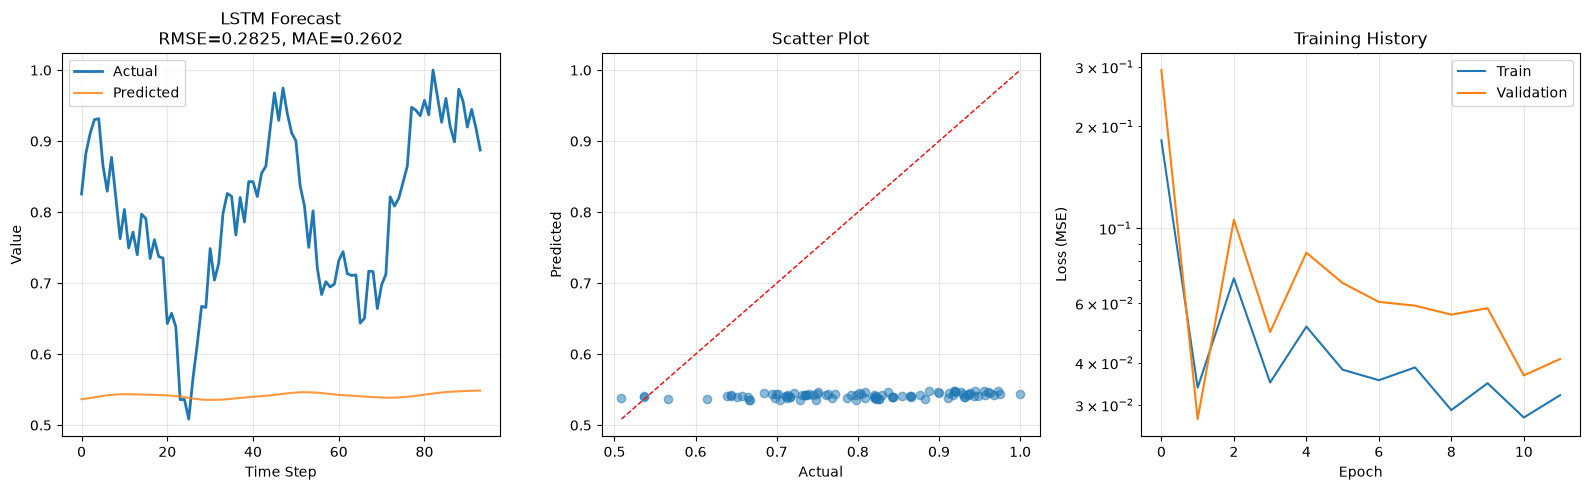

In [22]:
def main():
    print("=" * 60)
    print("LSTM — Long Short-Term Memory Demo")
    print("=" * 60)

    # ---- Data ----
    data = generate_synthetic_data(500)
    print(f"Data shape: {data.shape}")

    # ---- LSTMTimeSeries pipeline ----
    lstm_ts = LSTMTimeSeries(
        input_size=1, hidden_size=128, num_layers=2,
        dropout=0.2, learning_rate=0.001, device=device,
    )

    seq_length = 30
    X, y = lstm_ts.prepare_data(data, seq_length)

    split = int(len(X) * 0.8)
    X_train, X_test = X[:split], X[split:]
    y_train, y_test = y[:split], y[split:]
    print(f"Train: {X_train.shape}, Test: {X_test.shape}")

    # Train
    history = lstm_ts.fit(X_train, y_train, epochs=30, batch_size=32, patience=10)

    # Predict
    y_pred = lstm_ts.predict(X_test)

    # Plot
    lstm_ts.plot_results(y_test, y_pred, title="LSTM Forecast")

    # ---- MultivariateLSTM demo  (same synthetic data, treat as 1-feature) ----
    print("\n--- MultivariateLSTM with Attention ---")
    mv_model = MultivariateLSTM(input_size=1, hidden_size=64, num_layers=2)
    mv_model.to(device)

    tr_ds = TensorDataset(torch.FloatTensor(X_train), torch.FloatTensor(y_train))
    tr_loader = DataLoader(tr_ds, batch_size=32, shuffle=False)

    opt = optim.Adam(mv_model.parameters(), lr=0.001)
    mv_model.train()
    for epoch in range(15):
        epoch_loss = 0.0
        for bx, by in tr_loader:
            bx, by = bx.to(device), by.to(device)
            opt.zero_grad()
            loss = nn.MSELoss()(mv_model(bx), by)
            loss.backward()
            nn.utils.clip_grad_norm_(mv_model.parameters(), 1.0)
            opt.step()
            epoch_loss += loss.item() * bx.size(0)
        if (epoch + 1) % 5 == 0:
            print(f"  AttnLSTM Epoch {epoch+1}/15 | Loss: {epoch_loss/len(tr_loader.dataset):.6f}")

    mv_model.eval()
    with torch.no_grad():
        mv_pred = mv_model(torch.FloatTensor(X_test).to(device)).cpu().numpy()
    mv_rmse = float(np.sqrt(mean_squared_error(y_test, mv_pred)))
    print(f"  MultivariateLSTM + Attention RMSE: {mv_rmse:.4f}")

    # ---- Future forecast demo ----
    print("\n--- Multi-step Future Forecast ---")
    future_preds = lstm_ts.forecast_future(X_test[-1], steps=20, n_features=1)
    print(f"Next 20 forecasted values: {[f'{v:.2f}' for v in future_preds]}")

    print("\n" + "=" * 60)
    print("LSTM Advantages over RNN:")
    print("  1. Forget gate: decides what to discard from cell state")
    print("  2. Input gate: decides what new information to store")
    print("  3. Output gate: decides what to output from cell state")
    print("  4. Cell state preserves long-range dependencies")
    print("  5. Bidirectional variant captures past and future context")
    print("  6. Attention mechanism focuses on relevant time steps")
    print("=" * 60)


if __name__ == "__main__":
    main()


---
## GRU


In [23]:
import os
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

OUTPUT_DIR = os.getcwd()  # current working directory (Jupyter)
device = torch.device("cpu")
# Note: Change to torch.device("cuda" if torch.cuda.is_available() else "cpu") for GPU
print(f"Using device: {device}")
print("Output directory: Part-5/")


Using device: cpu
Output directory: Part-5/


## 1. Synthetic data generator


In [24]:
def generate_data(n_points=600, seed=42):
    rng = np.random.RandomState(seed)
    t = np.arange(n_points, dtype=np.float32)
    trend = 0.08 * t
    seasonal = 6.0 * np.sin(2 * np.pi * t / 40.0) + 3.0 * np.sin(2 * np.pi * t / 18.0)
    noise = rng.normal(0, 1.2, size=n_points)
    return (trend + seasonal + noise).reshape(-1, 1)


def create_sequences(data, seq_length):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i : i + seq_length])
        y.append(data[i + seq_length, -1])
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)


## 2. GRUForecaster


In [25]:
class GRUForecaster(nn.Module):
    """
    GRU-based forecaster.

    Parameters
    ----------
    input_size : int       Number of input features.
    hidden_size : int      Number of GRU hidden units.
    num_layers : int       Number of stacked GRU layers.
    dropout : float        Dropout between layers.
    bidirectional : bool   Use bidirectional GRU.
    """
    def __init__(self, input_size=1, hidden_size=128, num_layers=2,
                 dropout=0.2, bidirectional=False):
        super().__init__()
        num_directions = 2 if bidirectional else 1
        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            dropout=dropout if num_layers > 1 else 0.0,
            batch_first=True,
            bidirectional=bidirectional,
        )
        gru_out = hidden_size * num_directions
        self.fc = nn.Sequential(
            nn.Linear(gru_out, gru_out // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(gru_out // 2, 1),
        )

    def forward(self, x):
        # x: (batch, seq_len, input_size)
        out, _ = self.gru(x)
        return self.fc(out[:, -1, :]).squeeze(-1)


## 3. LSTM reference model (for comparison)


In [26]:
class LSTMForecaster(nn.Module):
    """Identical architecture to GRUForecaster but using LSTM."""
    def __init__(self, input_size=1, hidden_size=128, num_layers=2,
                 dropout=0.2, bidirectional=False):
        super().__init__()
        num_directions = 2 if bidirectional else 1
        self.lstm = nn.LSTM(
            input_size, hidden_size, num_layers,
            dropout=dropout if num_layers > 1 else 0.0,
            batch_first=True, bidirectional=bidirectional,
        )
        lstm_out = hidden_size * num_directions
        self.fc = nn.Sequential(
            nn.Linear(lstm_out, lstm_out // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(lstm_out // 2, 1),
        )

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :]).squeeze(-1)


## 4. compare_lstm_gru — same data, compare speed and metrics


In [27]:
def compare_lstm_gru(X_train, y_train, X_test, y_test, hidden_size=128, epochs=20):
    """
    Empirical comparison of LSTM vs GRU on identical data.

    Returns
    -------
    dict with RMSE, training time, and parameter count for each model.
    """
    results = {}
    for name, ModelClass in [("LSTM", LSTMForecaster), ("GRU", GRUForecaster)]:
        print(f"\nTraining {name} ...")
        model = ModelClass(
            input_size=X_train.shape[2],
            hidden_size=hidden_size,
            num_layers=2,
            dropout=0.2,
        ).to(device)

        loader = DataLoader(
            TensorDataset(torch.FloatTensor(X_train), torch.FloatTensor(y_train)),
            batch_size=32, shuffle=False,
        )
        criterion = nn.MSELoss()
        optimizer = optim.Adam(model.parameters(), lr=0.001)

        start = time.time()
        for epoch in range(1, epochs + 1):
            model.train()
            for bx, by in loader:
                bx, by = bx.to(device), by.to(device)
                optimizer.zero_grad()
                loss = criterion(model(bx), by)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            if epoch % 10 == 0:
                print(f"  {name} Epoch {epoch}/{epochs}")
        elapsed = time.time() - start

        model.eval()
        with torch.no_grad():
            preds = model(torch.FloatTensor(X_test).to(device)).cpu().numpy()

        rmse = float(np.sqrt(mean_squared_error(y_test, preds)))
        n_params = sum(p.numel() for p in model.parameters())
        results[name] = {"RMSE": rmse, "TrainTime(s)": elapsed, "Params": n_params}

        print(f"  {name} done — RMSE={rmse:.4f}, Time={elapsed:.2f}s, Params={n_params:,}")

    return results


## 5. GRU with Attention


In [28]:
class GRUAttention(nn.Module):
    """
    GRU with an additive attention mechanism.

    Instead of only using the last GRU output, attention computes a
    weighted average of all time steps, giving the model the ability
    to focus on the most informative parts of the sequence.
    """
    def __init__(self, input_size=1, hidden_size=128, num_layers=2, dropout=0.2):
        super().__init__()
        self.gru = nn.GRU(
            input_size, hidden_size, num_layers,
            dropout=dropout if num_layers > 1 else 0.0,
            batch_first=True,
        )
        self.attention = nn.Sequential(
            nn.Linear(hidden_size, hidden_size // 2),
            nn.Tanh(),
            nn.Linear(hidden_size // 2, 1),
        )
        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        # x: (batch, seq_len, input_size)
        gru_out, _ = self.gru(x)  # (batch, seq_len, hidden)
        # Attention weights
        attn = self.attention(gru_out).squeeze(-1)  # (batch, seq_len)
        attn_w = torch.softmax(attn, dim=1)
        # Context vector
        ctx = (gru_out * attn_w.unsqueeze(-1)).sum(dim=1)  # (batch, hidden)
        return self.fc(ctx).squeeze(-1)


## 6. MultivariateGRU with encoder-decoder style


In [29]:
class MultivariateGRU(nn.Module):
    """
    GRU encoder-decoder for multivariate time series.

    The encoder reads the input sequence and produces a hidden state.
    The decoder then maps that hidden state to a multi-step forecast.

    Useful for:
      - Predicting stock price from price + volume + index features
      - Forecasting temperature from temperature + humidity + pressure
    """
    def __init__(self, input_size, hidden_size=128, num_layers=2,
                 dropout=0.2, forecast_horizon=7):
        super().__init__()
        self.forecast_horizon = forecast_horizon
        self.encoder = nn.GRU(
            input_size, hidden_size, num_layers,
            dropout=dropout if num_layers > 1 else 0.0,
            batch_first=True,
        )
        self.decoder = nn.Sequential(
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_size, hidden_size // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_size // 2, forecast_horizon),
        )

    def forward(self, x):
        # x: (batch, seq_len, input_size)
        enc_out, _ = self.encoder(x)
        last_hidden = enc_out[:, -1, :]  # (batch, hidden)
        return self.decoder(last_hidden)  # (batch, forecast_horizon)


## 7. Plotting utility


In [30]:
def plot_gru_results(y_true, y_pred, title="GRU Forecast"):
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    mae = float(mean_absolute_error(y_true, y_pred))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(y_true, label="Actual", linewidth=2)
    axes[0].plot(y_pred, label="Predicted", alpha=0.8)
    axes[0].set_title(f"{title} — RMSE={rmse:.4f}, MAE={mae:.4f}")
    axes[0].set_xlabel("Time Step")
    axes[0].set_ylabel("Value")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    lo = min(y_true.min(), y_pred.min())
    hi = max(y_true.max(), y_pred.max())
    axes[1].scatter(y_true, y_pred, alpha=0.5)
    axes[1].plot([lo, hi], [lo, hi], "r--", linewidth=1)
    axes[1].set_xlabel("Actual")
    axes[1].set_ylabel("Predicted")
    axes[1].set_title("Scatter Plot")
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    path = os.path.join(OUTPUT_DIR, f"{title.lower().replace(' ', '_')}.png")
    print(f"Plot saved to: {os.path.basename(path)}")


## 8. Main demo


GRU — Gated Recurrent Unit Demo
Train: (456, 30, 1), Test: (114, 30, 1)

--- GRUForecaster ---
Parameters: 157,697
  Epoch   5/20 | Loss: 0.023006
  Epoch  10/20 | Loss: 0.008577
  Epoch  15/20 | Loss: 0.005999
  Epoch  20/20 | Loss: 0.005764
Plot saved to: gru_forecast.png

--- LSTM vs GRU Comparison ---

Training LSTM ...
  LSTM Epoch 10/15
  LSTM done — RMSE=0.0820, Time=2.73s, Params=207,489

Training GRU ...
  GRU Epoch 10/15
  GRU done — RMSE=0.0401, Time=22.62s, Params=157,697
  LSTM: RMSE=0.0820, Time=2.73s, Params=207,489
  GRU: RMSE=0.0401, Time=22.62s, Params=157,697

--- GRU with Attention ---
  Epoch   5/15 | Loss: 0.040627
  Epoch  10/15 | Loss: 0.015537
  Epoch  15/15 | Loss: 0.017083
  GRU+Attention RMSE: 0.1114

--- MultivariateGRU (multi-step forecast) ---
  MultivariateGRU (10-step forecast) trained for 10 epochs.

GRU Summary:
  1. Two gates: Reset and Update (vs LSTM's three)
  2. Fewer parameters -> faster training, less memory
  3. Comparable accuracy to LSTM on 

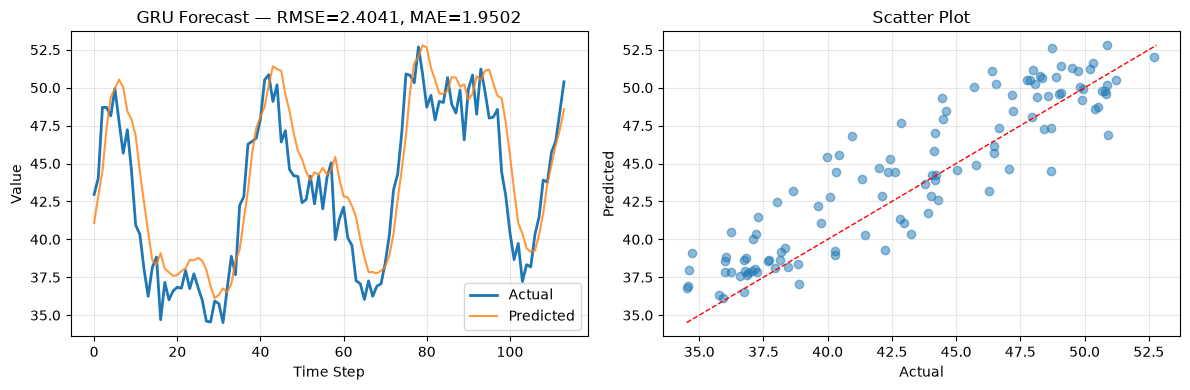

In [31]:
def main():
    print("=" * 60)
    print("GRU — Gated Recurrent Unit Demo")
    print("=" * 60)

    # ---- Data preparation ----
    raw = generate_data(600)
    scaler = MinMaxScaler()
    scaled = scaler.fit_transform(raw).flatten()

    seq_length = 30
    X, y = create_sequences(scaled.reshape(-1, 1), seq_length)

    split = int(len(X) * 0.8)
    X_train, X_test = X[:split], X[split:]
    y_train, y_test = y[:split], y[split:]
    print(f"Train: {X_train.shape}, Test: {X_test.shape}")

    # ---- GRUForecaster training ----
    print("\n--- GRUForecaster ---")
    model = GRUForecaster(input_size=1, hidden_size=128, num_layers=2, dropout=0.2).to(device)
    print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

    loader = DataLoader(
        TensorDataset(torch.FloatTensor(X_train), torch.FloatTensor(y_train)),
        batch_size=32, shuffle=False,
    )
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.MSELoss()

    for epoch in range(1, 21):
        model.train()
        epoch_loss = 0.0
        for bx, by in loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            loss = criterion(model(bx), by)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            epoch_loss += loss.item() * bx.size(0)
        if epoch % 5 == 0:
            print(f"  Epoch {epoch:3d}/20 | Loss: {epoch_loss/len(loader.dataset):.6f}")

    model.eval()
    with torch.no_grad():
        preds_scaled = model(torch.FloatTensor(X_test).to(device)).cpu().numpy()
    preds = scaler.inverse_transform(preds_scaled.reshape(-1, 1)).flatten()
    actuals = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()
    plot_gru_results(actuals, preds, title="GRU Forecast")

    # ---- Compare LSTM vs GRU ----
    print("\n--- LSTM vs GRU Comparison ---")
    comparison = compare_lstm_gru(X_train, y_train, X_test, y_test, hidden_size=128, epochs=15)
    for name, res in comparison.items():
        print(f"  {name}: RMSE={res['RMSE']:.4f}, Time={res['TrainTime(s)']:.2f}s, Params={res['Params']:,}")

    # ---- GRUAttention demo ----
    print("\n--- GRU with Attention ---")
    attn_model = GRUAttention(input_size=1, hidden_size=64, num_layers=2).to(device)
    attn_optim = optim.Adam(attn_model.parameters(), lr=0.001)
    attn_loader = DataLoader(
        TensorDataset(torch.FloatTensor(X_train), torch.FloatTensor(y_train)),
        batch_size=32, shuffle=False,
    )
    for epoch in range(1, 16):
        attn_model.train()
        loss_acc = 0.0
        for bx, by in attn_loader:
            bx, by = bx.to(device), by.to(device)
            attn_optim.zero_grad()
            loss = criterion(attn_model(bx), by)
            loss.backward()
            nn.utils.clip_grad_norm_(attn_model.parameters(), 1.0)
            attn_optim.step()
            loss_acc += loss.item() * bx.size(0)
        if epoch % 5 == 0:
            print(f"  Epoch {epoch:3d}/15 | Loss: {loss_acc/len(attn_loader.dataset):.6f}")

    attn_model.eval()
    with torch.no_grad():
        attn_pred = attn_model(torch.FloatTensor(X_test).to(device)).cpu().numpy()
    attn_rmse = float(np.sqrt(mean_squared_error(y_test, attn_pred)))
    print(f"  GRU+Attention RMSE: {attn_rmse:.4f}")

    # ---- MultivariateGRU demo (single-variate data, multiple-step output) ----
    print("\n--- MultivariateGRU (multi-step forecast) ---")
    mv_gru = MultivariateGRU(
        input_size=1, hidden_size=64, num_layers=2,
        dropout=0.2, forecast_horizon=10,
    ).to(device)
    # For multi-step, we need y with shape (n, forecast_horizon)
    y_multi = np.array([y[i:i+10] for i in range(len(y)-9)])  # slicing
    X_multi = X[:len(y_multi)]
    # Quick demo — just run a few epochs
    mv_loader = DataLoader(
        TensorDataset(torch.FloatTensor(X_multi), torch.FloatTensor(y_multi)),
        batch_size=32, shuffle=False,
    )
    mv_opt = optim.Adam(mv_gru.parameters(), lr=0.001)
    mv_gru.train()
    for epoch in range(10):
        for bx, by in mv_loader:
            bx, by = bx.to(device), by.to(device)
            mv_opt.zero_grad()
            loss = nn.MSELoss()(mv_gru(bx), by)
            loss.backward()
            nn.utils.clip_grad_norm_(mv_gru.parameters(), 1.0)
            mv_opt.step()
    print("  MultivariateGRU (10-step forecast) trained for 10 epochs.")

    print("\n" + "=" * 60)
    print("GRU Summary:")
    print("  1. Two gates: Reset and Update (vs LSTM's three)")
    print("  2. Fewer parameters -> faster training, less memory")
    print("  3. Comparable accuracy to LSTM on most tasks")
    print("  4. Rule: try GRU first, then LSTM if needed")
    print("  5. Supports attention, bidirectionality, and deep stacking")
    print("=" * 60)


if __name__ == "__main__":
    main()


---
## CNN Time Series


In [32]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

OUTPUT_DIR = os.getcwd()  # current working directory (Jupyter)
device = torch.device("cpu")
# Note: Change to torch.device("cuda" if torch.cuda.is_available() else "cpu") for GPU
print(f"Using device: {device}")
print("Output directory: Part-5/")


Using device: cpu
Output directory: Part-5/


## 1. Synthetic data


In [33]:
def generate_data(n_points=600, seed=42):
    rng = np.random.RandomState(seed)
    t = np.arange(n_points, dtype=np.float32)
    trend = 0.06 * t
    seasonal = 4.0 * np.sin(2 * np.pi * t / 50.0) + 2.0 * np.sin(2 * np.pi * t / 22.0)
    noise = rng.normal(0, 1.0, size=n_points)
    return (trend + seasonal + noise).reshape(-1, 1)


def create_sequences(data, seq_length):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i : i + seq_length])
        y.append(data[i + seq_length, -1])
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)


## 2. SimpleConv1D — basic Conv1D for time series


In [34]:
class SimpleConv1D(nn.Module):
    """
    A simple 1D CNN for time-series forecasting.

    Stacks multiple Conv1D + BatchNorm + MaxPool blocks, followed
    by global average pooling and a fully-connected output head.
    """
    def __init__(self, input_size=1, num_filters=None, kernel_sizes=None, dropout=0.2):
        super().__init__()
        if num_filters is None:
            num_filters = [64, 128, 256]
        if kernel_sizes is None:
            kernel_sizes = [5, 5, 3]

        self.conv_blocks = nn.ModuleList()
        in_ch = input_size
        for nf, ks in zip(num_filters, kernel_sizes):
            self.conv_blocks.append(nn.Sequential(
                nn.Conv1d(in_ch, nf, kernel_size=ks, padding=ks // 2, stride=1),
                nn.ReLU(),
                nn.BatchNorm1d(nf),
                nn.MaxPool1d(kernel_size=2),
                nn.Dropout(dropout),
            ))
            in_ch = nf

        self.fc = nn.Sequential(
            nn.Linear(num_filters[-1], 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        # x: (batch, seq_len, input_size)
        x = x.transpose(1, 2)           # (batch, input_size, seq_len)
        for block in self.conv_blocks:
            x = block(x)                # (batch, filters, reduced_len)
        x = torch.mean(x, dim=-1)       # global avg pool -> (batch, filters)
        return self.fc(x).squeeze(-1)


## 3. TCN — Temporal Convolutional Network with dilated causal convolutions


In [35]:
class TCNBlock(nn.Module):
    """
    A single TCN building block:
      - Two dilated convolutions with residual connection.
      - Dilation grows exponentially with depth (2^i).
    """
    def __init__(self, in_channels, out_channels, kernel_size, dilation, dropout=0.2):
        super().__init__()
        padding = (kernel_size - 1) * dilation // 2
        self.conv1 = nn.Conv1d(in_channels, out_channels, kernel_size,
                               dilation=dilation, padding=padding)
        self.conv2 = nn.Conv1d(out_channels, out_channels, kernel_size,
                               dilation=dilation, padding=padding)
        self.bn1 = nn.BatchNorm1d(out_channels)
        self.bn2 = nn.BatchNorm1d(out_channels)
        self.relu = nn.ReLU()
        self.drop = nn.Dropout(dropout)
        self.residual = (nn.Conv1d(in_channels, out_channels, 1)
                         if in_channels != out_channels else nn.Identity())

    def forward(self, x):
        residual = self.residual(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.drop(out)
        out = self.relu(self.bn2(self.conv2(out)))
        out = self.drop(out)
        return self.relu(out + residual)


class TCN(nn.Module):
    """
    Temporal Convolutional Network for time-series forecasting.

    Uses exponentially increasing dilation: 1, 2, 4, 8, ...
    This gives a large receptive field with relatively few layers.
    """
    def __init__(self, input_size=1, num_channels=None, kernel_size=3, dropout=0.2):
        super().__init__()
        if num_channels is None:
            num_channels = [64, 64, 64, 64]
        layers = []
        for i, nf in enumerate(num_channels):
            in_ch = input_size if i == 0 else num_channels[i - 1]
            dilation = 2 ** i
            layers.append(TCNBlock(in_ch, nf, kernel_size, dilation, dropout))
        self.net = nn.Sequential(*layers)
        self.fc = nn.Linear(num_channels[-1], 1)

    def forward(self, x):
        # x: (batch, seq_len, input_size)
        x = x.transpose(1, 2)       # (batch, input_size, seq_len)
        out = self.net(x)            # (batch, channels, seq_len)
        out = torch.mean(out, dim=-1)
        return self.fc(out).squeeze(-1)


## 4. CNN-LSTM hybrid


In [36]:
class CNNLSTM(nn.Module):
    """
    CNN-LSTM hybrid for time series.

    The CNN layers extract local features (automated preprocessing).
    The LSTM then models long-term temporal dependencies.
    This architecture has won many time-series competitions.
    """
    def __init__(self, input_size=1, cnn_filters=None, lstm_hidden=128,
                 lstm_layers=2, dropout=0.2):
        super().__init__()
        if cnn_filters is None:
            cnn_filters = [64, 128]

        cnn_layers = []
        in_ch = input_size
        for i, nf in enumerate(cnn_filters):
            cnn_layers.extend([
                nn.Conv1d(in_ch, nf, kernel_size=3, padding=1),
                nn.ReLU(),
                nn.BatchNorm1d(nf),
                nn.MaxPool1d(kernel_size=2) if i < len(cnn_filters) - 1 else nn.Identity(),
                nn.Dropout(dropout),
            ])
            in_ch = nf
        self.cnn = nn.Sequential(*cnn_layers)

        self.lstm = nn.LSTM(
            input_size=cnn_filters[-1],
            hidden_size=lstm_hidden,
            num_layers=lstm_layers,
            dropout=dropout if lstm_layers > 1 else 0.0,
            batch_first=True,
        )
        self.fc = nn.Sequential(
            nn.Linear(lstm_hidden, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        # x: (batch, seq_len, input_size)
        x = x.transpose(1, 2)           # (batch, input_size, seq_len)
        x = self.cnn(x)                  # (batch, cnn_filters[-1], reduced_len)
        x = x.transpose(1, 2)            # (batch, reduced_len, cnn_filters[-1])
        lstm_out, _ = self.lstm(x)
        return self.fc(lstm_out[:, -1, :]).squeeze(-1)


## 5. WaveNet-style block


In [37]:
class WaveNetBlock(nn.Module):
    """
    A single WaveNet block with gated activation.

    Gated activation: tanh(filter) * sigmoid(gate)
    Combined with residual and skip connections for stable training.
    """
    def __init__(self, channels, kernel_size, dilation, dropout=0.2):
        super().__init__()
        padding = (kernel_size - 1) * dilation // 2
        self.filter_conv = nn.Conv1d(channels, channels, kernel_size,
                                     dilation=dilation, padding=padding)
        self.gate_conv = nn.Conv1d(channels, channels, kernel_size,
                                   dilation=dilation, padding=padding)
        self.residual = nn.Conv1d(channels, channels, 1)
        self.skip = nn.Conv1d(channels, channels, 1)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        filt = torch.tanh(self.filter_conv(x))
        gate = torch.sigmoid(self.gate_conv(x))
        out = filt * gate
        res_out = self.residual(out) + x
        skip_out = self.skip(out)
        return self.drop(res_out), self.drop(skip_out)


class WaveNet(nn.Module):
    """
    Simplified WaveNet for time-series forecasting.

    Stacks multiple WaveNet blocks with increasing dilation.
    Accumulates skip connections for the final output.
    """
    def __init__(self, input_size=1, channels=64, num_blocks=4, kernel_size=3, dropout=0.2):
        super().__init__()
        self.input_proj = nn.Conv1d(input_size, channels, 1)
        self.blocks = nn.ModuleList()
        for i in range(num_blocks):
            self.blocks.append(WaveNetBlock(channels, kernel_size, dilation=2 ** i, dropout=dropout))
        self.output = nn.Sequential(
            nn.ReLU(),
            nn.Conv1d(channels, channels, 1),
            nn.ReLU(),
            nn.Conv1d(channels, 1, 1),
        )

    def forward(self, x):
        # x: (batch, seq_len, input_size)
        x = self.input_proj(x.transpose(1, 2))  # (batch, channels, seq_len)
        skip_accum = 0.0
        for block in self.blocks:
            x, skip = block(x)
            skip_accum = skip_accum + skip
        out = self.output(skip_accum)           # (batch, 1, seq_len)
        return out.squeeze(1).mean(dim=-1)       # (batch,)


## 6. CNN Autoencoder for anomaly detection


In [38]:
class CNNAutoencoder(nn.Module):
    """
    Convolutional autoencoder for time-series anomaly detection.

    The model learns to reconstruct normal patterns. High reconstruction
    error indicates an anomaly.

    Architecture:
      Encoder: Conv1D blocks with max-pooling -> bottleneck (latent)
      Decoder: ConvTranspose1D blocks to reconstruct the input
    """
    def __init__(self, seq_length, latent_dim=32):
        super().__init__()
        self.seq_length = seq_length
        # Encoder
        self.encoder = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=7, padding=3),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(32, 64, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(64, latent_dim, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1),
        )
        # Decoder
        self.decoder = nn.Sequential(
            nn.ConvTranspose1d(latent_dim, 64, kernel_size=4, stride=1),
            nn.ReLU(),
            nn.ConvTranspose1d(64, 32, kernel_size=4, stride=4),
            nn.ReLU(),
            nn.ConvTranspose1d(32, 1, kernel_size=4, stride=4),
        )

    def forward(self, x):
        # x: (batch, seq_len, 1)
        encoded = self.encoder(x.transpose(1, 2))       # (batch, latent, 1)
        reconstructed = self.decoder(encoded)            # (batch, 1, seq_len')
        reconstructed = reconstructed[:, :, :self.seq_length]
        return reconstructed.transpose(1, 2)             # (batch, seq_len, 1)


## 7. Plot utility


In [39]:
def plot_predictions(y_true, y_pred, title, filename):
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(y_true, label="Actual", linewidth=2)
    ax.plot(y_pred, label="Predicted", alpha=0.8)
    ax.set_title(f"{title} — RMSE={rmse:.4f}")
    ax.set_xlabel("Time Step")
    ax.set_ylabel("Value")
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    path = os.path.join(OUTPUT_DIR, filename)
    print(f"Plot saved to: {os.path.basename(path)}")


## 8. Main demo


1D CNN for Time Series — Demo
Train: (432, 60, 1), Test: (108, 60, 1)

SimpleConv1D — Parameters: 33,793
  Epoch   5/20 | Loss: 0.016394
  Epoch  10/20 | Loss: 0.008173
  Epoch  15/20 | Loss: 0.007834
  Epoch  20/20 | Loss: 0.016579
Plot saved to: simple_conv1d_forecast.png

TCN — Parameters: 87,937
  Epoch   5/15 | Loss: 0.033269
  Epoch  10/15 | Loss: 0.021651
  Epoch  15/15 | Loss: 0.007933
Plot saved to: tcn_forecast.png

CNN-LSTM — Parameters: 112,513
  Epoch   5/20 | Loss: 0.014879
  Epoch  10/20 | Loss: 0.013926
  Epoch  15/20 | Loss: 0.006903
  Epoch  20/20 | Loss: 0.015046
Plot saved to: cnn_lstm_forecast.png

WaveNet — Parameters: 34,433
  Epoch   5/15 | Loss: 0.029371
  Epoch  10/15 | Loss: 0.007796
  Epoch  15/15 | Loss: 0.006323
Plot saved to: wavenet_forecast.png

--- CNN Autoencoder — Anomaly Detection Demo ---
  AE Epoch   5/15 | Reconstruction Loss: 0.026272
  AE Epoch  10/15 | Reconstruction Loss: 0.008012
  AE Epoch  15/15 | Reconstruction Loss: 0.007451
  Reconstruc

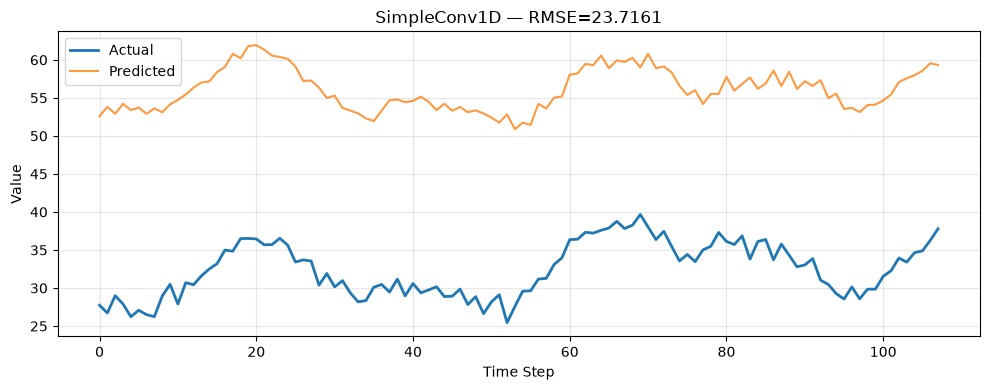

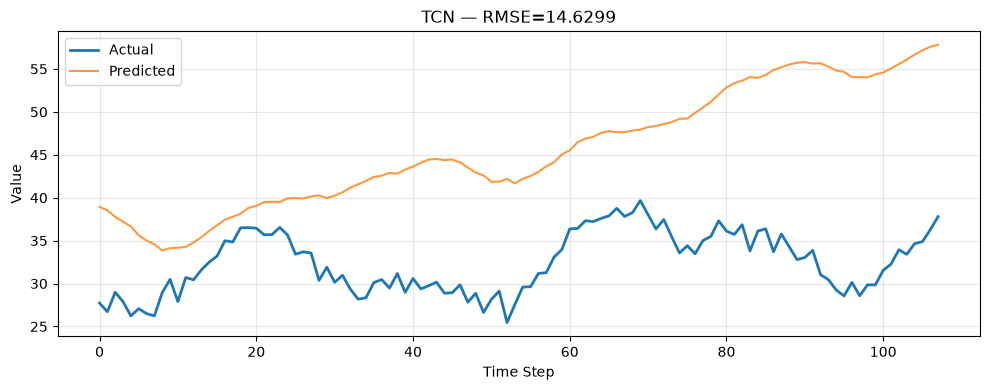

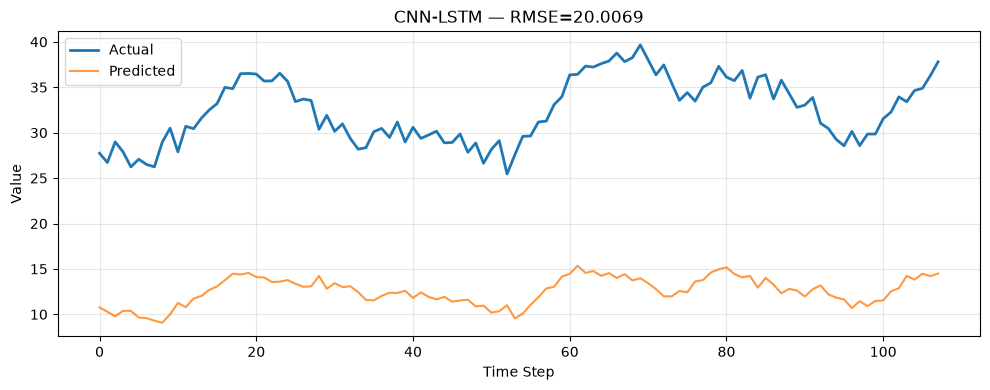

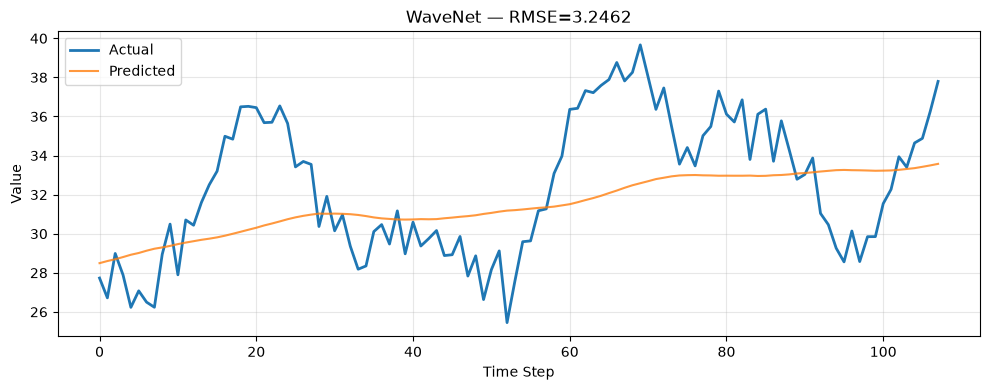

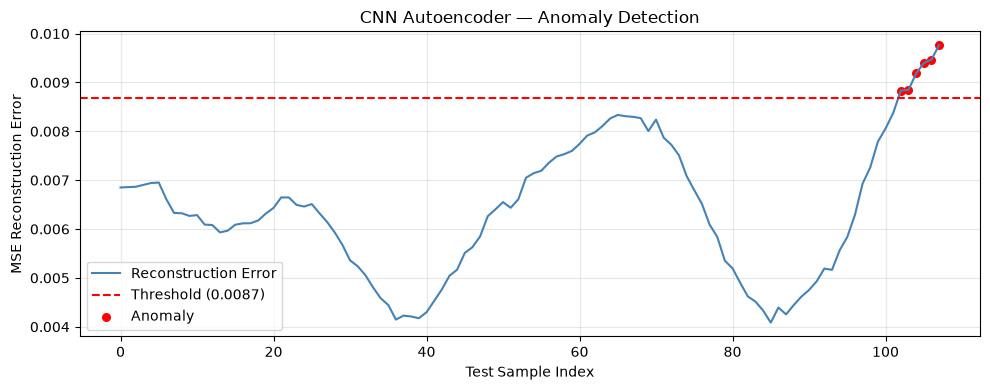

In [40]:
def main():
    print("=" * 60)
    print("1D CNN for Time Series — Demo")
    print("=" * 60)

    # ---- Data ----
    raw = generate_data(600)
    scaler = MinMaxScaler()
    scaled = scaler.fit_transform(raw).astype(np.float32)

    seq_length = 60
    X, y = create_sequences(scaled, seq_length)

    split = int(len(X) * 0.8)
    X_train, X_test = X[:split], X[split:]
    y_train, y_test = y[:split], y[split:]
    print(f"Train: {X_train.shape}, Test: {X_test.shape}")

    def make_loader(x, y, bs=32, shuffle=False):
        return DataLoader(
            TensorDataset(torch.FloatTensor(x), torch.FloatTensor(y)),
            batch_size=bs, shuffle=shuffle,
        )

    train_loader = make_loader(X_train, y_train)
    test_loader = make_loader(X_test, y_test)

    def train_model(model, loader, epochs=20, lr=0.001, name="Model"):
        model.to(device)
        opt = optim.Adam(model.parameters(), lr=lr)
        criterion = nn.MSELoss()
        n_params = sum(p.numel() for p in model.parameters())
        print(f"\n{name} — Parameters: {n_params:,}")
        for epoch in range(1, epochs + 1):
            model.train()
            loss_acc = 0.0
            for bx, by in loader:
                bx, by = bx.to(device), by.to(device)
                opt.zero_grad()
                loss = criterion(model(bx), by)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                opt.step()
                loss_acc += loss.item() * bx.size(0)
            if epoch % 5 == 0 or epoch == epochs:
                print(f"  Epoch {epoch:3d}/{epochs} | Loss: {loss_acc/len(loader.dataset):.6f}")
        return model

    def evaluate(model):
        model.eval()
        with torch.no_grad():
            preds = model(torch.FloatTensor(X_test).to(device)).cpu().numpy()
        preds = scaler.inverse_transform(preds.reshape(-1, 1)).flatten()
        actuals = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()
        return preds, actuals

    # SimpleConv1D
    cnn = SimpleConv1D(input_size=1, num_filters=[64, 128], kernel_sizes=[5, 3])
    cnn = train_model(cnn, train_loader, epochs=20, name="SimpleConv1D")
    preds, actuals = evaluate(cnn)
    plot_predictions(actuals, preds, "SimpleConv1D", "simple_conv1d_forecast.png")

    # TCN
    tcn = TCN(input_size=1, num_channels=[64, 64, 64, 64], kernel_size=3)
    tcn = train_model(tcn, train_loader, epochs=15, name="TCN")
    t_preds, t_actuals = evaluate(tcn)
    plot_predictions(t_actuals, t_preds, "TCN", "tcn_forecast.png")

    # CNN-LSTM
    cnn_lstm = CNNLSTM(input_size=1, cnn_filters=[64, 128], lstm_hidden=64, lstm_layers=2)
    cnn_lstm = train_model(cnn_lstm, train_loader, epochs=20, name="CNN-LSTM")
    cl_preds, cl_actuals = evaluate(cnn_lstm)
    plot_predictions(cl_actuals, cl_preds, "CNN-LSTM", "cnn_lstm_forecast.png")

    # WaveNet
    wavenet = WaveNet(input_size=1, channels=32, num_blocks=4, kernel_size=3)
    wavenet = train_model(wavenet, train_loader, epochs=15, name="WaveNet")
    wn_preds, wn_actuals = evaluate(wavenet)
    plot_predictions(wn_actuals, wn_preds, "WaveNet", "wavenet_forecast.png")

    # CNN Autoencoder for anomaly detection demo
    print("\n--- CNN Autoencoder — Anomaly Detection Demo ---")
    ae = CNNAutoencoder(seq_length=seq_length, latent_dim=32).to(device)
    ae_opt = optim.Adam(ae.parameters(), lr=0.001)
    ae_criterion = nn.MSELoss()

    for epoch in range(1, 16):
        ae.train()
        loss_acc = 0.0
        for bx, _ in train_loader:  # autoencoder: targets = inputs
            bx = bx.to(device)
            ae_opt.zero_grad()
            recon = ae(bx)
            loss = ae_criterion(recon, bx)
            loss.backward()
            ae_opt.step()
            loss_acc += loss.item() * bx.size(0)
        if epoch % 5 == 0:
            print(f"  AE Epoch {epoch:3d}/15 | Reconstruction Loss: {loss_acc/len(train_loader.dataset):.6f}")

    # Compute reconstruction errors and identify potential anomalies
    ae.eval()
    with torch.no_grad():
        recon_full = ae(torch.FloatTensor(X_test).to(device)).cpu().numpy()
    recon_errors = np.mean((recon_full.reshape(len(X_test), -1) - X_test.reshape(len(X_test), -1)) ** 2, axis=1)
    threshold = float(np.percentile(recon_errors, 95))
    anomalies = recon_errors > threshold
    print(f"  Reconstruction error threshold (95th percentile): {threshold:.6f}")
    print(f"  Potential anomalies detected: {anomalies.sum()} / {len(anomalies)}")

    plt.figure(figsize=(10, 4))
    plt.plot(recon_errors, label="Reconstruction Error", color="steelblue")
    plt.axhline(y=threshold, color="red", linestyle="--", label=f"Threshold ({threshold:.4f})")
    plt.scatter(np.where(anomalies)[0], recon_errors[anomalies], color="red", s=30, label="Anomaly")
    plt.xlabel("Test Sample Index")
    plt.ylabel("MSE Reconstruction Error")
    plt.title("CNN Autoencoder — Anomaly Detection")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "cnn_autoencoder_anomaly.png"), dpi=150)
    print("  Anomaly plot saved to: cnn_autoencoder_anomaly.png")

    print("\n" + "=" * 60)
    print("CNN for Time Series — Summary:")
    print("  1. Conv1D detects local patterns (spikes, trend changes)")
    print("  2. Dilated convolutions (TCN) expand receptive field efficiently")
    print("  3. CNN-LSTM hybrids offer excellent accuracy-speed trade-off")
    print("  4. WaveNet can model very long sequences (thousands of steps)")
    print("  5. CNN Autoencoders are effective for unsupervised anomaly detection")
    print("  6. CNNs are fully parallelizable — train much faster than RNNs")
    print("=" * 60)


if __name__ == "__main__":
    main()


---
## Attention Transformers


In [41]:
import os
import math
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

OUTPUT_DIR = os.getcwd()  # current working directory (Jupyter)
device = torch.device("cpu")
# Note: Change to torch.device("cuda" if torch.cuda.is_available() else "cpu") for GPU
print(f"Using device: {device}")
print("Output directory: Part-5/")


Using device: cpu
Output directory: Part-5/


## 1. Synthetic data


In [42]:
def generate_data(n_points=500, seed=42):
    rng = np.random.RandomState(seed)
    t = np.arange(n_points, dtype=np.float32)
    trend = 0.05 * t
    seasonal = 4.0 * np.sin(2 * np.pi * t / 40.0) + 2.0 * np.sin(2 * np.pi * t / 18.0)
    noise = rng.normal(0, 1.0, size=n_points)
    return (trend + seasonal + noise).reshape(-1, 1)


def create_sequences(data, seq_length):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i : i + seq_length])
        y.append(data[i + seq_length, -1])
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32)


## 2. Self-Attention and Causal Self-Attention


In [43]:
class SelfAttention(nn.Module):
    """
    Vanilla self-attention for time series.

    Each time step can attend to every other step (past and present).
    Returns attention weights for inspection.
    """
    def __init__(self, embed_dim):
        super().__init__()
        self.query = nn.Linear(embed_dim, embed_dim)
        self.key = nn.Linear(embed_dim, embed_dim)
        self.value = nn.Linear(embed_dim, embed_dim)
        self.scale = math.sqrt(embed_dim)

    def forward(self, x):
        # x: (batch, seq_len, embed_dim)
        Q = self.query(x)
        K = self.key(x)
        V = self.value(x)

        scores = torch.matmul(Q, K.transpose(-2, -1)) / self.scale  # (b, L, L)
        attn_weights = F.softmax(scores, dim=-1)
        out = torch.matmul(attn_weights, V)
        return out, attn_weights


class CausalSelfAttention(nn.Module):
    """
    Self-attention with a causal (triangular) mask.

    Each step can only attend to itself and earlier steps —
    future information is hidden. This is essential for forecasting.
    """
    def __init__(self, embed_dim):
        super().__init__()
        self.query = nn.Linear(embed_dim, embed_dim)
        self.key = nn.Linear(embed_dim, embed_dim)
        self.value = nn.Linear(embed_dim, embed_dim)
        self.scale = math.sqrt(embed_dim)

    def forward(self, x):
        B, L, D = x.shape
        Q = self.query(x)
        K = self.key(x)
        V = self.value(x)

        scores = torch.matmul(Q, K.transpose(-2, -1)) / self.scale  # (B, L, L)
        # Causal mask: upper triangle (diagonal=1) set to -inf
        causal_mask = torch.triu(torch.ones(L, L, device=x.device), diagonal=1).bool()
        scores = scores.masked_fill(causal_mask, float("-inf"))
        attn_weights = F.softmax(scores, dim=-1)
        out = torch.matmul(attn_weights, V)
        return out, attn_weights


## 3. Positional Encoding


In [44]:
class PositionalEncoding(nn.Module):
    """
    Sinusoidal positional encoding — tells the model where each step is
    in the sequence. Essential because self-attention is permutation-invariant.

    Uses alternating sin/cos functions at different frequencies.
    """
    def __init__(self, d_model, dropout=0.1, max_len=5000):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout)

        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model)
        )
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)  # (1, max_len, d_model)
        self.register_buffer("pe", pe)

    def forward(self, x):
        # x: (batch, seq_len, d_model)
        return self.dropout(x + self.pe[:, : x.size(1), :])


## 4. TimeSeriesTransformer


In [45]:
class TimeSeriesTransformer(nn.Module):
    """
    Transformer encoder for time-series forecasting.

    Components:
      1. Input projection (linear embedding)
      2. Positional encoding (sinusoidal)
      3. Transformer encoder layers (self-attention + FFN)
      4. Output head

    A causal mask is applied for auto-regressive forecasting.
    """
    def __init__(self, input_size=1, d_model=128, nhead=8,
                 num_layers=3, dropout=0.1):
        super().__init__()
        self.d_model = d_model
        self.input_proj = nn.Linear(input_size, d_model)
        self.pos_enc = PositionalEncoding(d_model, dropout, max_len=5000)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=d_model * 4,
            dropout=dropout, activation="gelu", batch_first=True,
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers)

        self.output_head = nn.Sequential(
            nn.Linear(d_model, 64),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1),
        )

    def _generate_causal_mask(self, seq_len):
        mask = torch.triu(torch.ones(seq_len, seq_len), diagonal=1).bool()
        return mask.to(next(self.parameters()).device)

    def forward(self, x):
        # x: (batch, seq_len, input_size)
        x = self.input_proj(x) * math.sqrt(self.d_model)
        x = self.pos_enc(x)

        causal_mask = self._generate_causal_mask(x.size(1))
        x = self.transformer(x, mask=causal_mask)    # (batch, seq_len, d_model)

        return self.output_head(x[:, -1, :]).squeeze(-1)


## 5. Reference models for benchmarking


In [46]:
class LSTMForecaster(nn.Module):
    def __init__(self, input_size=1, hidden_size=128, num_layers=2):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=0.2)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :]).squeeze(-1)


class GRUForecaster(nn.Module):
    def __init__(self, input_size=1, hidden_size=128, num_layers=2):
        super().__init__()
        self.gru = nn.GRU(input_size, hidden_size, num_layers, batch_first=True, dropout=0.2)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.gru(x)
        return self.fc(out[:, -1, :]).squeeze(-1)


class CNNLSTM(nn.Module):
    def __init__(self, input_size=1):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv1d(input_size, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.BatchNorm1d(64),
            nn.MaxPool1d(2),
            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.BatchNorm1d(128),
        )
        self.lstm = nn.LSTM(128, 64, batch_first=True)
        self.fc = nn.Linear(64, 1)

    def forward(self, x):
        x = x.transpose(1, 2)
        x = self.cnn(x).transpose(1, 2)
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :]).squeeze(-1)


class TCN(nn.Module):
    def __init__(self, input_size=1, channels=64, num_levels=4):
        super().__init__()
        layers = []
        for i in range(num_levels):
            in_ch = input_size if i == 0 else channels
            dilation = 2 ** i
            layers.append(nn.Sequential(
                nn.Conv1d(in_ch, channels, 3, dilation=dilation, padding=dilation),
                nn.ReLU(),
                nn.BatchNorm1d(channels),
                nn.Dropout(0.2),
            ))
        self.net = nn.Sequential(*layers)
        self.fc = nn.Linear(channels, 1)

    def forward(self, x):
        x = self.net(x.transpose(1, 2))
        return self.fc(x.mean(dim=-1)).squeeze(-1)


## 6. Benchmark function comparing DL models


In [47]:
def benchmark_dl_models(X_train, y_train, X_test, y_test, epochs=15):
    """
    Train and compare multiple deep-learning architectures on the same data.

    Returns
    -------
    dict : {model_name: {"RMSE": float, "Parameters": int}}
    """
    input_size = X_train.shape[2]
    models = {
        "LSTM": LSTMForecaster(input_size=input_size, hidden_size=128, num_layers=2),
        "GRU": GRUForecaster(input_size=input_size, hidden_size=128, num_layers=2),
        "TCN": TCN(input_size=input_size, channels=64, num_levels=4),
        "CNN-LSTM": CNNLSTM(input_size=input_size),
        "Transformer": TimeSeriesTransformer(
            input_size=input_size, d_model=64, nhead=4, num_layers=2, dropout=0.1,
        ),
    }

    train_ds = TensorDataset(
        torch.FloatTensor(X_train), torch.FloatTensor(y_train),
    )
    train_loader = DataLoader(train_ds, batch_size=32, shuffle=False)

    results = {}
    for name, model in models.items():
        print(f"  Training {name} ...", end=" ")
        model = model.to(device)
        n_params = sum(p.numel() for p in model.parameters())
        opt = optim.Adam(model.parameters(), lr=0.001)
        criterion = nn.MSELoss()

        model.train()
        for epoch in range(epochs):
            epoch_loss = 0.0
            for bx, by in train_loader:
                bx, by = bx.to(device), by.to(device)
                opt.zero_grad()
                loss = criterion(model(bx), by)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                opt.step()
                epoch_loss += loss.item() * bx.size(0)

        model.eval()
        with torch.no_grad():
            preds = model(torch.FloatTensor(X_test).to(device)).cpu().numpy()
        rmse = float(np.sqrt(mean_squared_error(y_test, preds)))
        results[name] = {"RMSE": rmse, "Parameters": n_params}
        print(f"RMSE={rmse:.4f}, Params={n_params:,}")

    return results


## 7. Plot utilities


In [48]:
def plot_attention_weights(attn_weights, title, filename):
    """Visualize attention weight matrix."""
    fig, ax = plt.subplots(figsize=(6, 5))
    # attn_weights: (batch, L, L) — take first sample in batch
    im = ax.imshow(attn_weights[0].detach().cpu().numpy(), cmap="viridis", aspect="auto")
    ax.set_title(title)
    ax.set_xlabel("Key position")
    ax.set_ylabel("Query position")
    plt.colorbar(im, ax=ax)
    plt.tight_layout()
    path = os.path.join(OUTPUT_DIR, filename)
    print(f"  Attention plot saved to: {filename}")


def plot_forecast(y_true, y_pred, title, filename):
    rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(y_true, label="Actual", linewidth=2)
    ax.plot(y_pred, label="Predicted", alpha=0.8)
    ax.set_title(f"{title} — RMSE={rmse:.4f}")
    ax.set_xlabel("Time Step")
    ax.set_ylabel("Value")
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    path = os.path.join(OUTPUT_DIR, filename)
    print(f"  Plot saved to: {filename}")


## 8. Main demo


In [51]:
class InformerBlock(nn.Module):
    def __init__(self, d_model, nhead, dropout=0.1):
        super().__init__()

        self.attention = nn.MultiheadAttention(
            embed_dim=d_model,
            num_heads=nhead,
            dropout=dropout,
            batch_first=True,
        )

        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)

        self.feed_forward = nn.Sequential(
            nn.Linear(d_model, d_model * 4),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model * 4, d_model),
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # x: (batch, sequence_length, d_model)
        attn_out, _ = self.attention(x, x, x, need_weights=False)
        x = self.norm1(x + self.dropout(attn_out))

        ff_out = self.feed_forward(x)
        x = self.norm2(x + self.dropout(ff_out))

        return x


Attention Mechanisms & Transformers for Time Series
Train: (376, 30, 1), Test: (94, 30, 1)

--- Self-Attention Visualization ---
  Attention plot saved to: self_attention_weights.png
  Attention plot saved to: causal_attention_weights.png

--- TimeSeriesTransformer Training ---
Transformer parameters: 104,321
  Epoch   5/20 | Loss: 0.010504
  Epoch  10/20 | Loss: 0.006183
  Epoch  15/20 | Loss: 0.005174
  Epoch  20/20 | Loss: 0.004591
  Plot saved to: transformer_forecast.png

--- Informer-style Block Demo ---
  Informer block output shape: torch.Size([4, 30, 64])

--- DL Model Benchmark ---
  Training LSTM ... RMSE=0.0770, Params=199,297
  Training GRU ... RMSE=0.0466, Params=149,505
  Training TCN ... RMSE=0.3270, Params=37,889
  Training CNN-LSTM ... RMSE=0.1550, Params=75,073
  Training Transformer ... RMSE=0.0659, Params=104,321
  Benchmark plot saved to: model_benchmark.png

Attention & Transformers — Summary:
  1. Self-attention lets every step attend to every other step
  2. Ca

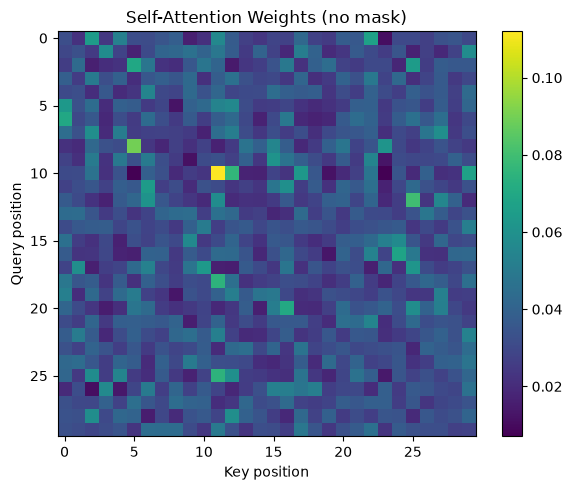

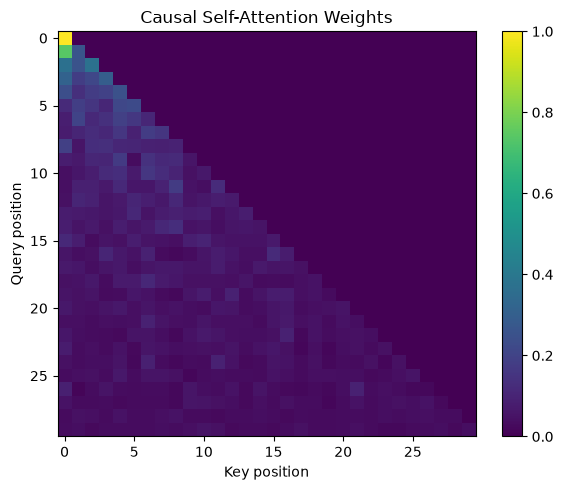

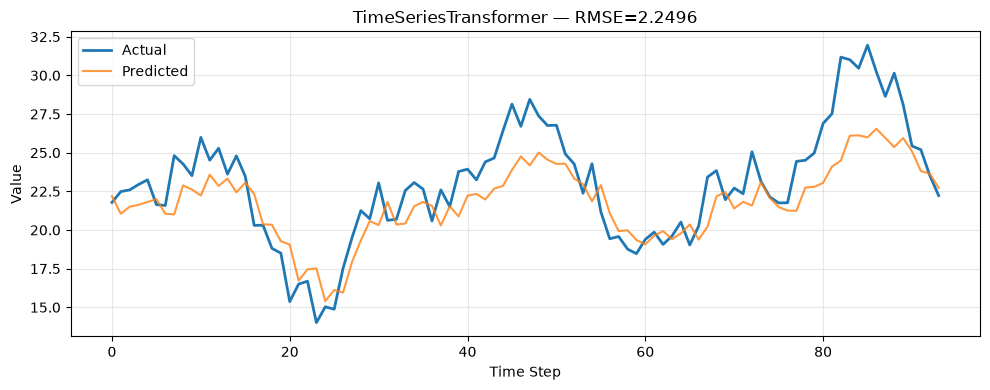

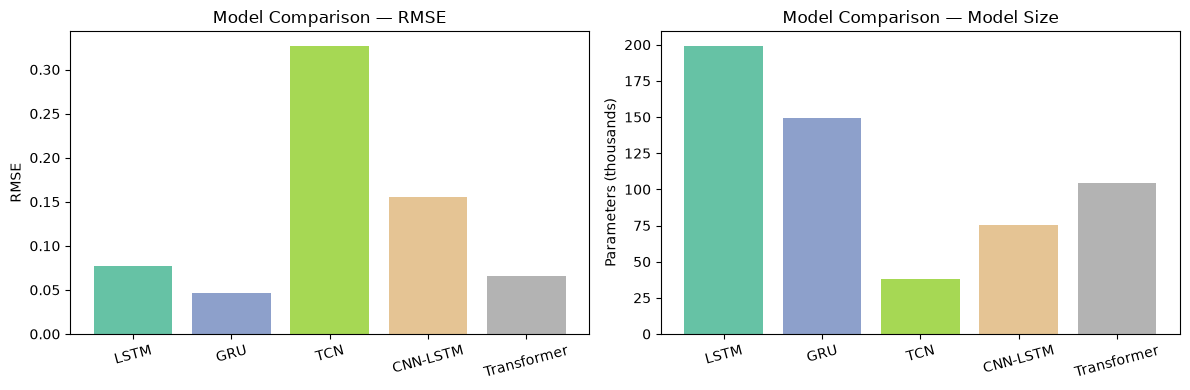

In [52]:
def main():
    print("=" * 60)
    print("Attention Mechanisms & Transformers for Time Series")
    print("=" * 60)

    # ---- Data ----
    raw = generate_data(500)
    scaler = MinMaxScaler()
    scaled = scaler.fit_transform(raw).astype(np.float32)

    seq_length = 30
    X, y = create_sequences(scaled, seq_length)

    split = int(len(X) * 0.8)
    X_train, X_test = X[:split], X[split:]
    y_train, y_test = y[:split], y[split:]
    print(f"Train: {X_train.shape}, Test: {X_test.shape}")

    # ---- Self-Attention demo ----
    print("\n--- Self-Attention Visualization ---")
    embed_dim = 32
    dummy_seq = torch.randn(1, seq_length, embed_dim)
    sa = SelfAttention(embed_dim)
    _, attn_w = sa(dummy_seq)
    plot_attention_weights(attn_w, "Self-Attention Weights (no mask)", "self_attention_weights.png")

    caus = CausalSelfAttention(embed_dim)
    _, causal_w = caus(dummy_seq)
    plot_attention_weights(causal_w, "Causal Self-Attention Weights", "causal_attention_weights.png")

    # ---- TimeSeriesTransformer training ----
    print("\n--- TimeSeriesTransformer Training ---")
    transformer = TimeSeriesTransformer(
        input_size=1, d_model=64, nhead=4, num_layers=2, dropout=0.1,
    ).to(device)
    n_params = sum(p.numel() for p in transformer.parameters())
    print(f"Transformer parameters: {n_params:,}")

    train_loader = DataLoader(
        TensorDataset(torch.FloatTensor(X_train), torch.FloatTensor(y_train)),
        batch_size=32, shuffle=False,
    )
    opt = optim.Adam(transformer.parameters(), lr=0.0005)
    criterion = nn.MSELoss()

    for epoch in range(1, 21):
        transformer.train()
        loss_acc = 0.0
        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)
            opt.zero_grad()
            loss = criterion(transformer(bx), by)
            loss.backward()
            nn.utils.clip_grad_norm_(transformer.parameters(), 1.0)
            opt.step()
            loss_acc += loss.item() * bx.size(0)
        if epoch % 5 == 0:
            print(f"  Epoch {epoch:3d}/20 | Loss: {loss_acc/len(train_loader.dataset):.6f}")

    transformer.eval()
    with torch.no_grad():
        tf_preds_scaled = transformer(torch.FloatTensor(X_test).to(device)).cpu().numpy()
    tf_preds = scaler.inverse_transform(tf_preds_scaled.reshape(-1, 1)).flatten()
    tf_actuals = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()
    plot_forecast(tf_actuals, tf_preds, "TimeSeriesTransformer", "transformer_forecast.png")

    # ---- InformerBlock demo ----
    print("\n--- Informer-style Block Demo ---")
    informer = InformerBlock(d_model=64, nhead=4, dropout=0.1).to(device)
    dummy_in = torch.randn(4, 30, 64).to(device)
    dummy_out = informer(dummy_in)
    print(f"  Informer block output shape: {dummy_out.shape}")

    # ---- Benchmark ----
    print("\n--- DL Model Benchmark ---")
    results = benchmark_dl_models(X_train, y_train, X_test, y_test, epochs=15)

    # Bar chart of results
    names = list(results.keys())
    rmse_vals = [results[n]["RMSE"] for n in names]
    param_vals = [results[n]["Parameters"] / 1e3 for n in names]  # in thousands

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    colors = plt.cm.Set2(np.linspace(0, 1, len(names)))

    axes[0].bar(names, rmse_vals, color=colors)
    axes[0].set_ylabel("RMSE")
    axes[0].set_title("Model Comparison — RMSE")
    axes[0].tick_params(axis="x", rotation=15)

    axes[1].bar(names, param_vals, color=colors)
    axes[1].set_ylabel("Parameters (thousands)")
    axes[1].set_title("Model Comparison — Model Size")
    axes[1].tick_params(axis="x", rotation=15)

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "model_benchmark.png"), dpi=150)
    print("  Benchmark plot saved to: model_benchmark.png")

    print("\n" + "=" * 60)
    print("Attention & Transformers — Summary:")
    print("  1. Self-attention lets every step attend to every other step")
    print("  2. Causal mask prevents future leakage (critical for forecasting)")
    print("  3. Positional encoding provides order information to the model")
    print("  4. Transformers are data-hungry — need more data than RNNs")
    print("  5. Informer / ProbSparse attention reduces O(L^2) to O(L log L)")
    print("  6. For practical tasks, CNN+LSTM often beats Transformers on small data")
    print("=" * 60)


if __name__ == "__main__":
    main()


---
## Part-5 Complete!

All lessons finished successfully.
